##Project Objective
##Analyze global and country-level transportation-related CO₂ emissions to understand historical emission trends, compare transportation emissions across countries, identify major emission contributors, and develop a machine learning model to explore future transportation emission patterns.
#Research Questions
1. How have global transportation-related CO₂ emissions changed over time?
2. Which countries contribute the most to transportation-related CO₂ emissions?
3. How do transportation emissions vary across different countries?
4. How have transportation emissions changed in selected countries over the years?
5. What percentage of total national CO₂ emissions comes from transportation?
6. Can historical transportation emission patterns support future emission prediction?
7. Which countries show increasing or decreasing transportation emission trends?
8.	Which countries have the highest transportation CO₂ emissions per capita?	Transport_CO2_Per_Capita
9.	Which countries depend most on transportation as a source of CO₂ emissions?	Transport_Share_Pct
10.	Is transportation emissions growth faster in some countries than others?	Transport_YoY_Growth_Pct
11.	Which countries have successfully reduced transportation emissions over time?	Historical trends, YoY growth
12.	How large are non-transport emissions compared with transportation emissions in each country?	Non_Transport_CO2
13.	Is higher total CO₂ emissions per capita associated with higher transportation emissions per capita?	Total_CO2_Per_Capita, Transport_CO2_Per_Capita
14.	Do countries with high transportation emissions also have a high transportation share of total emissions?	Transport_Share_Pct, transport CO₂
15.	Which countries experienced the biggest increases or decreases in transportation emissions over the study period?	Absolute change and percentage change
16.	Are transportation emissions becoming more or less significant in national carbon footprints over time?	Historical Transport_Share_Pct
17.	Which countries have high transportation emissions despite relatively low total emissions per capita?	Per-capita comparison



##Data Sources
- Our World in Data (OWID) – CO₂ emissions from transport.
- Our World in Data (OWID) – Total CO₂ emissions by country.
- Our World in Data (OWID) – Population data.
- Kaggle – Supplementary transportation and emissions datasets, if required.
#Tools
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- GitHub
- Looker Studio

In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option('display.max_columns', None)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Project initialized successfully!")


Project initialized successfully!


In [ ]:
# Load datasets
transport_df = pd.read_csv('co2-emissions-transport.csv')
total_df = pd.read_csv('annual-co2-emissions-per-country.csv')
population_df = pd.read_csv('population.csv')

# Display dataset information
print("Transportation dataset:", transport_df.shape)
print("Total CO2 dataset:", total_df.shape)
print("Population dataset:", population_df.shape)

print("\nTransportation dataset columns:")
print(transport_df.columns.tolist())

print("\nTotal emissions columns:")
print(total_df.columns.tolist())

print("\nPopulation columns:")
print(population_df.columns.tolist())

Transportation dataset: (6884, 4)
Total CO2 dataset: (30219, 4)
Population dataset: (58824, 4)

Transportation dataset columns:
['Entity', 'Code', 'Year', 'Carbon dioxide emissions from transport']

Total emissions columns:
['Entity', 'Code', 'Year', 'Annual CO₂ emissions']

Population columns:
['Entity', 'Code', 'Year', 'Population']


In [ ]:
#data clean and merge

transport_value = [c for c in transport_df.columns
                   if c not in ["Entity", "Code", "Year"]][0]
population_value= [c for c in population_df.columns
                   if c not in ["Entity" , "Code" , "Year"]][0]
total_value = [c for c in total_df.columns
               if c not in ["Entity" , "Code" , "Year"]][0]

transport = transport_df[["Entity","Code","Year",transport_value]
].rename(columns={transport_value:"Transport_CO2"})

total = total_df[
    ["Entity", "Code", "Year", total_value]
].rename(columns={total_value: "Total_CO2"})

population = population_df[["Entity","Code","Year",population_value]
].rename(columns={population_value:"Population"})

df=(
    transport[["Entity", "Code", "Year","Transport_CO2"]]
    .merge(total[["Code", "Year","Total_CO2"]],on=["Year","Code"],how="left")
    .merge(population[["Code","Year","Population"]],on=["Year","Code"],how="left"))
df.head()

,Entity,Code,Year,Transport_CO2,Total_CO2,Population
0,Afghanistan,AFG,1990,970000,2038981.9,12045664
1,Afghanistan,AFG,1991,930000,1932622.0,12238879
2,Afghanistan,AFG,1992,740000,1500374.0,13278983
3,Afghanistan,AFG,1993,740000,1505263.0,14943175
4,Afghanistan,AFG,1994,730000,1468623.0,16250800


In [ ]:
#detect missing data and remove them

df.isna().sum()

,0
Entity,0
Code,0
Year,0
Transport_CO2,0
Total_CO2,5
Population,0


In [ ]:
df[df.isna().any(axis=1)]

,Entity,Code,Year,Transport_CO2,Total_CO2,Population
1926,Eritrea,ERI,1990,0,NaN,2032749
1927,Eritrea,ERI,1991,0,NaN,1919575
1928,Eritrea,ERI,1992,110000,NaN,1798750
1929,Eritrea,ERI,1993,210000,NaN,1856017
4200,Namibia,NAM,1990,0,NaN,1369309


In [ ]:
#remove missing values

df = df.dropna(
    subset=["Code", "Transport_CO2", "Total_CO2", "Population"]
).copy()

In [ ]:
# Remove continents, regions, income groups and global aggregates

non_countries = [
    "Africa", "Asia", "Europe", "European Union (27)",
    "North America", "South America", "Oceania", "World",
    "High-income countries",
    "Low-income countries",
    "Lower-middle-income countries",
    "Upper-middle-income countries"
]

df= df[~df['Entity'].isin(non_countries)].copy()

# Sort data
df = df.sort_values(
    ["Entity", "Year"]
).reset_index(drop=True)

In [ ]:
df.describe()

,Year,Transport_CO2,Total_CO2,Population
count,6471.000000,6.471000e+03,6.471000e+03,6.471000e+03
mean,2006.547056,2.895773e+07,1.523292e+08,3.512314e+07
std,9.794831,1.319744e+08,7.074735e+08,1.323591e+08
min,1990.000000,0.000000e+00,3.664000e+03,1.776000e+03
25%,1998.000000,5.249995e+05,1.572384e+06,1.881729e+06
50%,2007.000000,2.710000e+06,9.761064e+06,7.305659e+06
75%,2015.000000,1.358500e+07,6.151424e+07,2.299062e+07
max,2023.000000,1.807720e+09,1.230309e+10,1.438070e+09



KPI Name	Formula	What It Reveals
1. Transport Share of Total CO2 (%)	(Transport_CO2 / Total_CO2) * 100	How heavily a country's carbon footprint is driven by transportation vs. electricity, manufacturing, or agriculture.
2. Transport CO2 per Capita (tonnes/person)	Transport_CO2 / Population	The average transport emissions generated per citizen—allows fair comparison between massive populations (like India or China) and smaller nations.
3. Total CO2 per Capita (tonnes/person)	Total_CO2 / Population	A country's overall per-person carbon footprint, useful as a benchmark against its transport per-capita rate.
4. Non-Transport CO2 (tonnes)	Total_CO2 - Transport_CO2	Isolates emissions from all other sectors (power, industry, buildings) so you can see whether transport is growing faster than the rest of the economy.
5. Year-over-Year (YoY) Transport Growth (%)	Transport_CO2.pct_change() * 100 (grouped by Code)	Tracks annual spikes or drops in transport emissions (e.g., spotting the sharp 2020 COVID-19 lockdo


In [ ]:
df.sort_values(by=["Code","Year"]).copy()

#Transport Share (%)
df["Transport_Share_Pct"] = (df["Transport_CO2"] / df["Total_CO2"]) * 100

#Transport CO2 per Capita (tonnes per person)
df["Transport_CO2_Per_Capita"] = df["Transport_CO2"] / df["Population"]

#Total CO2 per Capita (tonnes per person)
df["Total_CO2_Per_Capita"] = df["Total_CO2"] / df["Population"]

#Non-Transport CO2 (tonnes)
df["Non_Transport_CO2"] = df["Total_CO2"] - df["Transport_CO2"]

#Year-over-Year Transport Emissions Growth (%)
df["Transport_YoY_Growth_Pct"] = df.groupby("Code")["Transport_CO2"].pct_change() * 100

df.tail()

,Entity,Code,Year,Transport_CO2,Total_CO2,Population,Transport_Share_Pct,Transport_CO2_Per_Capita,Total_CO2_Per_Capita,Non_Transport_CO2,Transport_YoY_Growth_Pct
6466,Zimbabwe,ZWE,2019,2220000,10225605.0,15271377,21.710207,0.145370,0.669593,8005605.0,-15.267176
6467,Zimbabwe,ZWE,2020,1510000,8434772.0,15526887,17.902084,0.097251,0.543237,6924772.0,-31.981982
6468,Zimbabwe,ZWE,2021,1720000,10130522.0,15797220,16.978395,0.108880,0.641285,8410522.0,13.907285
6469,Zimbabwe,ZWE,2022,2330000,12256476.0,16069061,19.010358,0.144999,0.762738,9926476.0,35.465116
6470,Zimbabwe,ZWE,2023,2500000,15096099.0,16340829,16.560570,0.152991,0.923827,12596099.0,7.296137


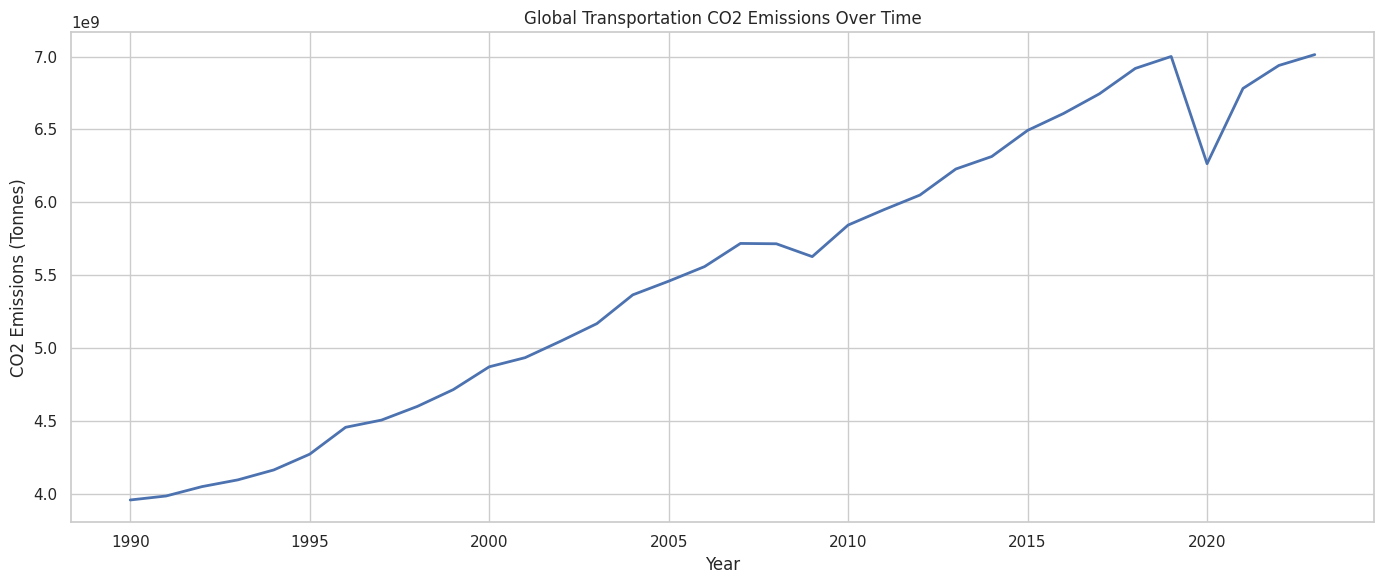

In [ ]:

# Aggregate emissions by year
global_trend = df.groupby("Year")["Transport_CO2"].sum().reset_index()

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=global_trend,
    x="Year",
    y="Transport_CO2",
    linewidth=2
)

plt.title("Global Transportation CO2 Emissions Over Time")
plt.xlabel("Year")
plt.ylabel("CO2 Emissions (Tonnes)")
plt.tight_layout()
plt.show()


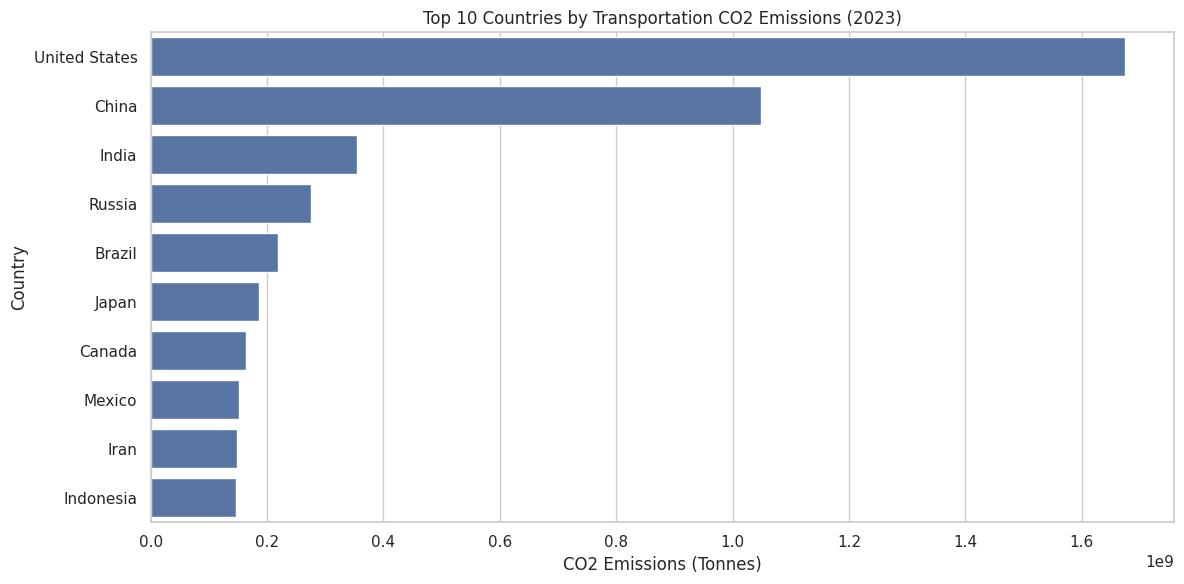

In [ ]:

latest_year = df["Year"].max()

top_countries = (
    df[df["Year"] == latest_year]
    .sort_values("Transport_CO2", ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries,
    x="Transport_CO2",
    y="Entity"
)

plt.title(f"Top 10 Countries by Transportation CO2 Emissions ({latest_year})")
plt.xlabel("CO2 Emissions (Tonnes)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


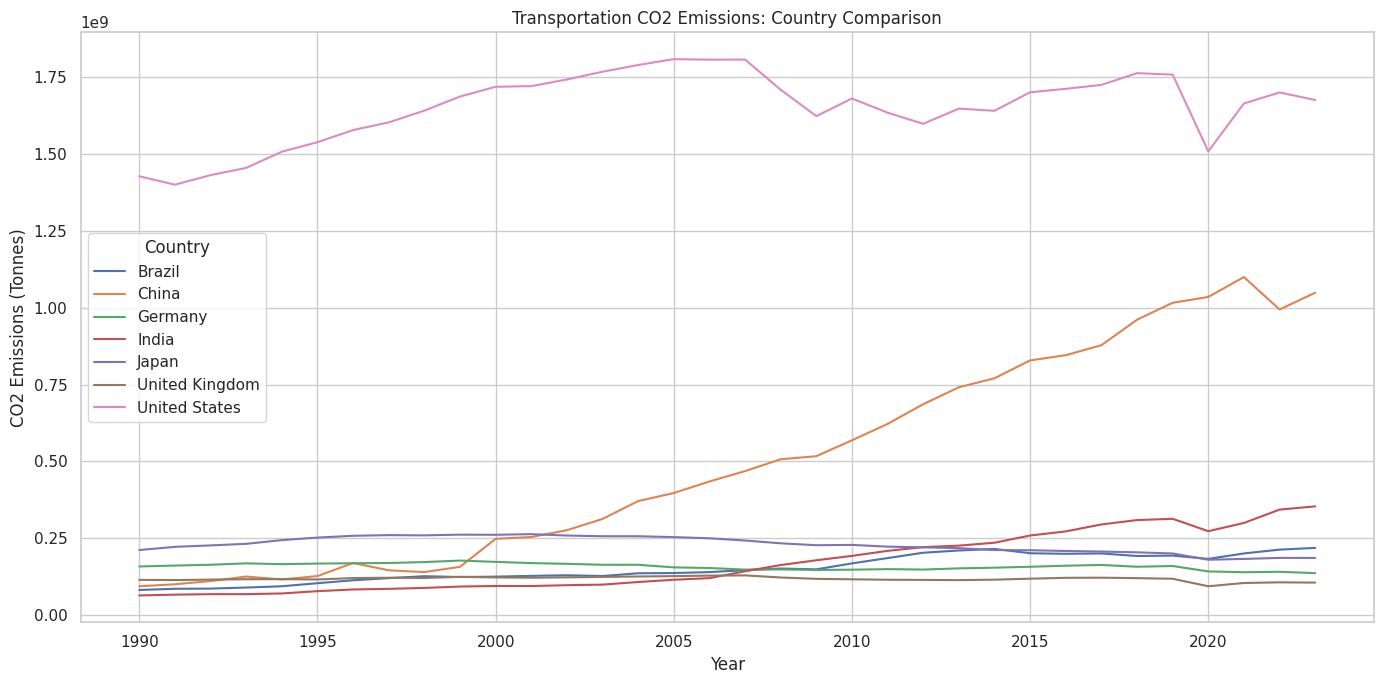

In [ ]:

selected_countries = [
    "India",
    "United States",
    "China",
    "Germany",
    "United Kingdom",
    "Japan",
    "Brazil"
]

country_trend = df[df["Entity"].isin(selected_countries)]

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=country_trend,
    x="Year",
    y="Transport_CO2",
    hue="Entity"
)

plt.title("Transportation CO2 Emissions: Country Comparison")
plt.xlabel("Year")
plt.ylabel("CO2 Emissions (Tonnes)")
plt.legend(title="Country")
plt.tight_layout()
plt.show()

In [ ]:
#Prepare forecasting features


# OBJECTIVE: Compare forecasting models for country-level transportation CO2 emissions.

import pandas as pd
import numpy as np

ml_df = df.copy()
ml_df = ml_df.sort_values(["Code", "Year"]).copy()

# Historical features
ml_df["Lag_1"] = ml_df.groupby("Code")["Transport_CO2"].shift(1)
ml_df["Lag_2"] = ml_df.groupby("Code")["Transport_CO2"].shift(2)
ml_df["Lag_3"] = ml_df.groupby("Code")["Transport_CO2"].shift(3)

ml_df["Rolling_Mean_3"] = (
    ml_df.groupby("Code")["Transport_CO2"]
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

# Keep rows with sufficient historical data
ml_df = ml_df.dropna(
    subset=["Lag_1", "Lag_2", "Lag_3", "Rolling_Mean_3"]
).copy()

print("Dataset shape:", ml_df.shape)
print("Available years:", ml_df["Year"].min(), "-", ml_df["Year"].max())


Dataset shape: (5898, 15)
Available years: 1993 - 2023


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Features and target
features = [
    "Code",
    "Year",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Rolling_Mean_3"
]

target = "Transport_CO2"

# Models
def create_models():
    def make_preprocessor():
        return ColumnTransformer([
            ("country", OneHotEncoder(handle_unknown="ignore"), ["Code"]),
            ("numeric", StandardScaler(), [
                "Year", "Lag_1", "Lag_2", "Lag_3", "Rolling_Mean_3"
            ])
        ])

    return {
        "Linear Regression": Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", LinearRegression())
        ]),

        "Ridge Regression": Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", Ridge(alpha=10))
        ]),

        "Random Forest": Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", RandomForestRegressor(
                n_estimators=200,
                max_depth=12,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            ))
        ])
    }

# Test different forecast evaluation windows
test_windows = [5, 7, 10]
all_results = []

available_years = sorted(ml_df["Year"].unique())

for window in test_windows:

    test_year_list = available_years[-window:]
    first_test_year = test_year_list[0]

    train = ml_df[ml_df["Year"] < first_test_year]
    test = ml_df[ml_df["Year"].isin(test_year_list)]

    X_train = train[features]
    X_test = test[features]
    y_train = train[target]
    y_test = test[target]

    print(f"\nTesting last {window} years")
    print("Training records:", len(train))
    print("Testing records:", len(test))
    print("Test period:", test_year_list[0], "-", test_year_list[-1])

    # Previous-year baseline
    baseline_pred = X_test["Lag_1"].to_numpy()

    all_results.append({
        "Test_Years": window,
        "Model": "Previous Year Baseline",
        "MAE": mean_absolute_error(y_test, baseline_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, baseline_pred)),
        "R2": r2_score(y_test, baseline_pred)
    })

    # Train and evaluate ML models
    for name, model in create_models().items():

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        all_results.append({
            "Test_Years": window,
            "Model": name,
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
            "R2": r2_score(y_test, predictions)
        })

# Final comparison
comparison_df = pd.DataFrame(all_results)

comparison_df = comparison_df.sort_values(
    ["Test_Years", "MAE"]
).reset_index(drop=True)

display(comparison_df.round(4))



Testing last 5 years
Training records: 4943
Testing records: 955
Test period: 2019 - 2023

Testing last 7 years
Training records: 4561
Testing records: 1337
Test period: 2017 - 2023

Testing last 10 years
Training records: 3988
Testing records: 1910
Test period: 2014 - 2023


,Test_Years,Model,MAE,RMSE,R2
0,5,Ridge Regression,2.274130e+06,1.100424e+07,0.9943
1,5,Previous Year Baseline,2.338869e+06,1.162053e+07,0.9937
2,5,Linear Regression,2.467385e+06,1.281834e+07,0.9923
3,5,Random Forest,2.943833e+06,1.465806e+07,0.9900
4,7,Ridge Regression,1.973438e+06,9.498631e+06,0.9958
5,7,Previous Year Baseline,2.038594e+06,1.024702e+07,0.9951
6,7,Linear Regression,2.113148e+06,1.096337e+07,0.9944
7,7,Random Forest,2.474968e+06,1.224348e+07,0.9930
8,10,Ridge Regression,1.751827e+06,8.164295e+06,0.9968
9,10,Previous Year Baseline,1.782476e+06,8.902182e+06,0.9962


In [ ]:
#Ridge Regression consistently outperforms the baseline,
#Linear Regression and Random Forest across all three test windows.

#Train the final Ridge Regression model



# FINAL MODEL: Ridge Regression

from sklearn.base import clone

final_model = create_models()["Ridge Regression"]

X_all = ml_df[features]
y_all = ml_df["Transport_CO2"]

final_model.fit(X_all, y_all)

print("Final Ridge Regression model trained.")
print("Training records:", len(X_all))
print("Historical period:", ml_df["Year"].min(), "-", ml_df["Year"].max())


Final Ridge Regression model trained.
Training records: 5898
Historical period: 1993 - 2023


In [ ]:
#Generate annual transport CO2 predictions for every country from 2024 to 2030.

forecast_rows = []

for code, group in df.groupby("Code"):

    group = group.sort_values("Year")

    # Use countries with data through the latest historical year
    if group["Year"].max() != df["Year"].max():
        continue

    history = group["Transport_CO2"].dropna().tolist()

    if len(history) < 3:
        continue

    entity = group["Entity"].iloc[0]
    last_year = int(group["Year"].max())

    for year in range(last_year + 1, 2031):

        input_row = pd.DataFrame([{
            "Code": code,
            "Year": year,
            "Lag_1": history[-1],
            "Lag_2": history[-2],
            "Lag_3": history[-3],
            "Rolling_Mean_3": np.mean(history[-3:])
        }])

        prediction = final_model.predict(input_row[features])[0]

        prediction = max(0, prediction)

        forecast_rows.append({
            "Entity": entity,
            "Code": code,
            "Year": year,
            "Transport_CO2": prediction,
            "Record_Type": "Prediction"
        })

        # Add prediction to history for recursive forecasting
        history.append(prediction)

forecast_df = pd.DataFrame(forecast_rows)

display(forecast_df.head(10))

,Entity,Code,Year,Transport_CO2,Record_Type
0,Afghanistan,AFG,2024,4.643548e+06,Prediction
1,Afghanistan,AFG,2025,4.674288e+06,Prediction
2,Afghanistan,AFG,2026,4.710190e+06,Prediction
3,Afghanistan,AFG,2027,4.740958e+06,Prediction
4,Afghanistan,AFG,2028,4.760696e+06,Prediction
5,Afghanistan,AFG,2029,4.773190e+06,Prediction
6,Afghanistan,AFG,2030,4.777705e+06,Prediction
7,Angola,AGO,2024,8.444051e+06,Prediction
8,Angola,AGO,2025,8.653129e+06,Prediction
9,Angola,AGO,2026,8.814678e+06,Prediction


In [ ]:
# Merge historical observations and annual predictions.

historical_data = df.copy()
historical_data["Record_Type"] = "Historical"

country_df_with_predictions = pd.concat(
    [historical_data, forecast_df],
    ignore_index=True
)

country_df_with_predictions = (
    country_df_with_predictions
    .sort_values(["Entity", "Year"])
    .reset_index(drop=True)
)

print("Years in final dataset:")
print(sorted(country_df_with_predictions["Year"].unique()))

print("\nRecord types:")
print(country_df_with_predictions["Record_Type"].value_counts())

Years in final dataset:
[np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026), np.int64(2027), np.int64(2028), np.int64(2029), np.int64(2030)]

Record types:
Record_Type
Historical    6471
Prediction    1337
Name: count, dtype: int64


Group countries with similar transportation-emissions patterns using clustering

In [ ]:
# Objective: Group countries by their historical transportation-emissions patterns.
#Prepare country-level clustering data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Replace infinite growth values
df["Transport_YoY_Growth_Pct"] = (
    df["Transport_YoY_Growth_Pct"].replace([np.inf, -np.inf], np.nan)
)

# Create one row per country
cluster_df = df.groupby(["Entity", "Code"]).agg(
    Avg_Transport_CO2=("Transport_CO2", "mean"),
    Avg_Transport_Per_Capita=("Transport_CO2_Per_Capita", "mean"),
    Avg_Transport_Share=("Transport_Share_Pct", "mean"),
    Avg_Transport_Growth=("Transport_YoY_Growth_Pct", "mean")
).reset_index()

# Keep rows with complete feature values
cluster_df = cluster_df.replace([np.inf, -np.inf], np.nan)
cluster_df = cluster_df.dropna()

features = [
    "Avg_Transport_CO2",
    "Avg_Transport_Per_Capita",
    "Avg_Transport_Share",
    "Avg_Transport_Growth"
]

X = cluster_df[features]

# Standardise features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Countries available for clustering:", len(cluster_df))
cluster_df.head()

Countries available for clustering: 190


,Entity,Code,Avg_Transport_CO2,Avg_Transport_Per_Capita,Avg_Transport_Share,Avg_Transport_Growth
0,Afghanistan,AFG,2.548235e+06,0.086477,51.354890,7.550791
1,Albania,ALB,1.661176e+06,0.555622,40.409786,4.318913
2,Algeria,DZA,2.891735e+07,0.795493,22.820507,3.489082
3,Angola,AGO,4.146176e+06,0.169386,21.102621,10.004252
4,Antigua and Barbuda,ATG,1.897058e+05,2.339663,43.767776,2.328455


In [ ]:
# Objective: Automatically select the best K, assign country clusters, and save results.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test different cluster counts
k_scores = {}

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled_v2)
    k_scores[k] = silhouette_score(X_scaled_v2, labels)

# Select the highest silhouette score
best_k = max(k_scores, key=k_scores.get)

print("Silhouette scores:")
for k, score in k_scores.items():
    print(f"K={k}: {score:.4f}")

print(f"\nSelected K: {best_k}")
print(f"Best silhouette score: {k_scores[best_k]:.4f}")

# Fit final model
final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_df["Final_Cluster"] = final_kmeans.fit_predict(X_scaled_v2)

# Cluster profile
final_cluster_summary = (
    cluster_df.groupby("Final_Cluster")[features_v2]
    .mean()
    .round(2)
)

display(final_cluster_summary)

# Export final results
# cluster_df.to_csv(
#     "final_transport_emissions_clusters.csv",
#     index=False
# )

print("Final clustering results exported successfully.")

Silhouette scores:
K=2: 0.3580
K=3: 0.3736
K=4: 0.4096
K=5: 0.3626
K=6: 0.3433

Selected K: 4
Best silhouette score: 0.4096


,Avg_Transport_Per_Capita,Avg_Transport_Share,Avg_Transport_Growth
Final_Cluster,,,
0,1.07,22.14,3.42
1,0.41,50.85,5.52
2,0.20,18.73,-57.14
3,5.57,30.24,2.51


Final clustering results exported successfully.


In [ ]:
# Objective: Give each final cluster a meaningful research interpretation.

cluster_labels = {
    0: "Moderate Transport Share and Emissions",
    1: "High Transport Share, Low Per-Capita Emissions",
    2: "Low Emissions with Negative Growth",
    3: "High Per-Capita Transport Emissions"
}

cluster_interpretations = {
    0: "Countries with moderate per-capita transport emissions, a moderate transport share, and positive average growth.",
    1: "Countries with low per-capita transport emissions but a high proportion of national CO2 emissions from transport.",
    2: "Countries with the lowest per-capita transport emissions and strongly negative average transport growth.",
    3: "Countries with the highest per-capita transport emissions and a substantial transport share of national CO2 emissions."
}

cluster_df["Cluster_Name"] = cluster_df["Final_Cluster"].map(cluster_labels)
cluster_df["Cluster_Interpretation"] = cluster_df["Final_Cluster"].map(cluster_interpretations)

display(
    cluster_df[
        ["Entity", "Code", "Final_Cluster", "Cluster_Name"]
    ].head(10)
)

,Entity,Code,Final_Cluster,Cluster_Name
0,Afghanistan,AFG,1,"High Transport Share, Low Per-Capita Emissions"
1,Albania,ALB,1,"High Transport Share, Low Per-Capita Emissions"
2,Algeria,DZA,0,Moderate Transport Share and Emissions
3,Angola,AGO,0,Moderate Transport Share and Emissions
4,Antigua and Barbuda,ATG,0,Moderate Transport Share and Emissions
5,Argentina,ARG,0,Moderate Transport Share and Emissions
6,Armenia,ARM,0,Moderate Transport Share and Emissions
7,Australia,AUS,3,High Per-Capita Transport Emissions
8,Austria,AUT,0,Moderate Transport Share and Emissions
9,Azerbaijan,AZE,0,Moderate Transport Share and Emissions


In [ ]:
# Objective: Combine historical emissions, 2030 predictions, and K-Means clusters.

# Select one cluster record per country
country_clusters = cluster_df[
    [
        "Code",
        "Final_Cluster",
        "Cluster_Name",
        "Cluster_Interpretation"
    ]
].drop_duplicates(subset="Code")

# Merge with historical and predicted data
final_project_df = country_df_with_predictions.merge(
    country_clusters,
    on="Code",
    how="left"
)

# Sort by country and year
final_project_df = final_project_df.sort_values(
    ["Entity", "Year"]
).reset_index(drop=True)

display(final_project_df.head())

,Entity,Code,Year,Transport_CO2,Total_CO2,Population,Transport_Share_Pct,Transport_CO2_Per_Capita,Total_CO2_Per_Capita,Non_Transport_CO2,Transport_YoY_Growth_Pct,Record_Type,Final_Cluster,Cluster_Name,Cluster_Interpretation
0,Afghanistan,AFG,1990,970000.0,2038981.9,12045664.0,47.572762,0.080527,0.169271,1068981.9,NaN,Historical,1.0,"High Transport Share, Low Per-Capita Emissions",Countries with low per-capita transport emissi...
1,Afghanistan,AFG,1991,930000.0,1932622.0,12238879.0,48.121154,0.075987,0.157908,1002622.0,-4.123711,Historical,1.0,"High Transport Share, Low Per-Capita Emissions",Countries with low per-capita transport emissi...
2,Afghanistan,AFG,1992,740000.0,1500374.0,13278983.0,49.321036,0.055727,0.112989,760374.0,-20.430108,Historical,1.0,"High Transport Share, Low Per-Capita Emissions",Countries with low per-capita transport emissi...
3,Afghanistan,AFG,1993,740000.0,1505263.0,14943175.0,49.160844,0.049521,0.100732,765263.0,0.000000,Historical,1.0,"High Transport Share, Low Per-Capita Emissions",Countries with low per-capita transport emissi...
4,Afghanistan,AFG,1994,730000.0,1468623.0,16250800.0,49.706426,0.044921,0.090372,738623.0,-1.351351,Historical,1.0,"High Transport Share, Low Per-Capita Emissions",Countries with low per-capita transport emissi...


In [ ]:
# Objective: Save the complete project dataset.

final_project_df.to_csv(
    "project_final_transport_emissions_dataset.csv",
    index=False
)

print("Final project dataset exported successfully.")

Final project dataset exported successfully.
